# Playing styles inside each role

A fullback who scores and a fullback who never shoots are both fullbacks. This notebook splits each role into styles, using the 2025-26 z-scored per-90 stats for players with at least 900 minutes. Goalkeepers are already out of the file.

The style names are proposals. They live in `data/processed/cluster_names.csv`, which is the file to edit by hand. The player assignments read whatever name is in that file.

## How a style is chosen

For each role we try two to six clusters and keep the number with the best silhouette score. Silhouette asks whether a player sits closer to his own group than to the next one. We will not go past five clusters, so each role stays explainable in a meeting.

We then refit that same number of clusters with ten different random seeds. The adjusted Rand index says whether the groups come back the same. Below 0.8, the role is unstable and the picture should not be trusted.

The scatter is a flat view of the same stats. Principal components are the directions along which players in that role differ most. The axis label is the share of the spread that direction captures. Tottenham players are ringed and named.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.cluster import cluster_playing_styles

LABELS = {
    "goals_per90": "Goals per 90",
    "non_penalty_goals_per90": "Non-penalty goals per 90",
    "assists_per90": "Assists per 90",
    "shots_per90": "Shots per 90",
    "shots_on_target_per90": "Shots on target per 90",
    "crosses_per90": "Crosses per 90",
    "tackles_won_per90": "Tackles won per 90",
    "interceptions_per90": "Interceptions per 90",
    "fouls_committed_per90": "Fouls committed per 90",
    "fouls_drawn_per90": "Fouls drawn per 90",
    "offsides_per90": "Offsides per 90",
    "shot_accuracy": "Shot accuracy",
    "goals_per_shot": "Goals per shot",
}
ROLE_ORDER = ["CB", "FB", "CM", "AM_W", "ST"]
ROLE_TITLE = {
    "CB": "Centre-backs",
    "FB": "Fullbacks",
    "CM": "Central midfielders",
    "AM_W": "Attacking midfielders and wingers",
    "ST": "Strikers",
}
COLORS = ["#132257", "#C4A35A", "#2F6F4E", "#8C4A3A", "#4C6CB3"]

result = cluster_playing_styles()
players = result["players"]
names = result["names"]
diagnostics = result["diagnostics"]
features = result["features"]

def feature_phrase(pairs_text):
    parts = []
    for piece in pairs_text.split(", "):
        feature, value = piece.rsplit(" ", 1)
        parts.append(f"{LABELS.get(feature, feature)} {value}")
    return ", ".join(parts)

def show_role(position_group):
    info = diagnostics[position_group]
    subset = players.loc[players["position_group"] == position_group].reset_index(drop=True)
    coords = info["pca"]["coords"]
    subset = subset.copy()
    subset["pc1"] = coords[:, 0]
    subset["pc2"] = coords[:, 1]
    role_names = names.loc[names["position_group"] == position_group].sort_values("cluster_id")

    score_table = pd.DataFrame(
        {"k": list(info["scores"]), "silhouette": [round(value, 3) for value in info["scores"].values()]}
    )
    print(ROLE_TITLE[position_group])
    display(score_table)
    stability = info["stability"]
    state = "stable" if stability["stable"] else "unstable"
    print(
        f"Chosen k = {info['k']} (silhouette {info['silhouette']:.3f}). "
        f"Stability ARI = {stability['mean_ari']:.3f} ({state})."
    )

    variance = info["pca"]["explained_variance_ratio"]
    fig, ax = plt.subplots(figsize=(9, 6.5))
    for cluster_id, colour in zip(role_names["cluster_id"], COLORS):
        chunk = subset.loc[subset["cluster_id"] == cluster_id]
        label = role_names.loc[role_names["cluster_id"] == cluster_id, "cluster_name"].iloc[0]
        others = chunk.loc[chunk["team"] != "Tottenham"]
        ax.scatter(others["pc1"], others["pc2"], s=18, alpha=0.75, color=colour, label=label)
    spurs = subset.loc[subset["team"] == "Tottenham"]
    ax.scatter(
        spurs["pc1"],
        spurs["pc2"],
        s=70,
        facecolors="none",
        edgecolors="black",
        linewidths=1.4,
        zorder=4,
        label="Tottenham",
    )
    for row in spurs.itertuples(index=False):
        ax.annotate(row.player, (row.pc1, row.pc2), fontsize=8, xytext=(5, 4), textcoords="offset points")
    ax.set_xlabel(f"PC1 ({variance[0] * 100:.0f}% of variance)")
    ax.set_ylabel(f"PC2 ({variance[1] * 100:.0f}% of variance)")
    ax.set_title(ROLE_TITLE[position_group])
    ax.legend(frameon=False, loc="best")
    fig.tight_layout()
    plt.show()

    for style in role_names.itertuples(index=False):
        members = subset.loc[subset["cluster_id"] == style.cluster_id]
        typical = members.nsmallest(3, "distance_to_centroid")
        spurs_here = members.loc[members["team"] == "Tottenham", "player"].tolist()
        table = pd.DataFrame(
            {
                "Style": [style.cluster_name],
                "Players": [int(style.size)],
                "High": [feature_phrase(style.high_features)],
                "Low": [feature_phrase(style.low_features)],
                "Most typical": [", ".join(typical["player"].tolist())],
                "Spurs": [", ".join(spurs_here) if spurs_here else "none"],
            }
        )
        display(table)


## Centre-backs

Centre-backs


,k,silhouette
0,2,0.223
1,3,0.136
2,4,0.134
3,5,0.139
4,6,0.117


Chosen k = 2 (silhouette 0.223). Stability ARI = 1.000 (stable).


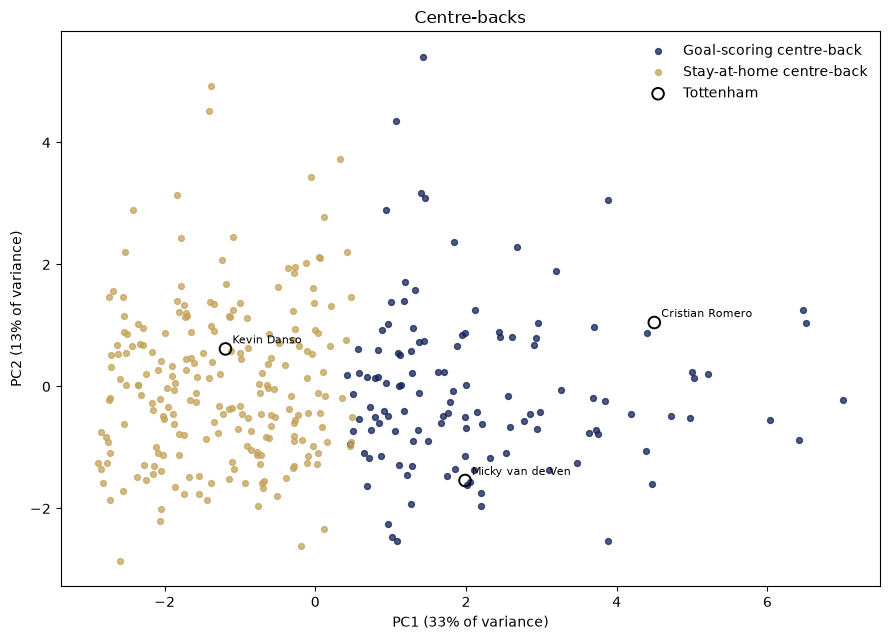

,Style,Players,High,Low,Most typical,Spurs
0,Goal-scoring centre-back,123,"Goals per 90 (+1.13), Non-penalty goals per 90...","Tackles won per 90 (-0.11), Interceptions per ...","Abdelhamid Ait Boudlal, Marc Pubill, Amir Rrah...","Cristian Romero, Micky van de Ven"


,Style,Players,High,Low,Most typical,Spurs
0,Stay-at-home centre-back,216,"Fouls drawn per 90 (+0.09), Fouls committed pe...","Goals per 90 (-0.58), Non-penalty goals per 90...","Vitor Reis, Moustapha Mbow, Simone Canestrelli",Kevin Danso


In [2]:
show_role("CB")


## Fullbacks

Fullbacks


,k,silhouette
0,2,0.210
1,3,0.114
2,4,0.102
3,5,0.114
4,6,0.116


Chosen k = 2 (silhouette 0.210). Stability ARI = 1.000 (stable).


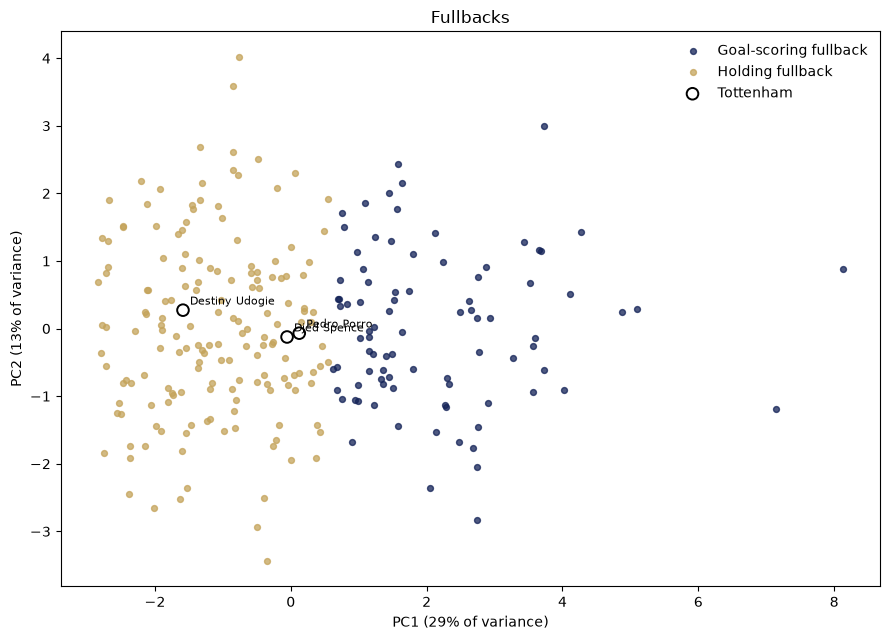

,Style,Players,High,Low,Most typical,Spurs
0,Goal-scoring fullback,88,"Goals per shot (+1.02), Goals per 90 (+0.99), ...","Interceptions per 90 (-0.13), Fouls drawn per ...","Matty Cash, Andrea Cambiaso, Robin Gosens",none


,Style,Players,High,Low,Most typical,Spurs
0,Holding fullback,168,"Fouls committed per 90 (+0.03), Interceptions ...","Non-penalty goals per 90 (-0.56), Goals per 90...","Pep Chavarría, Zeki Çelik, Johan Mojica","Destiny Udogie, Djed Spence, Pedro Porro"


In [3]:
show_role("FB")


## Central midfielders

Central midfielders


,k,silhouette
0,2,0.228
1,3,0.146
2,4,0.146
3,5,0.153
4,6,0.144


Chosen k = 2 (silhouette 0.228). Stability ARI = 0.979 (stable).


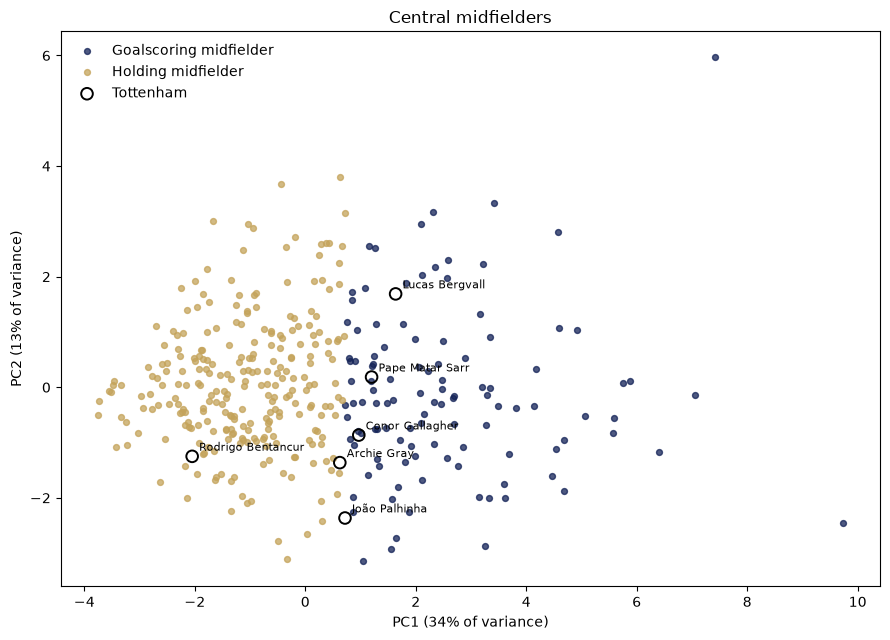

,Style,Players,High,Low,Most typical,Spurs
0,Goalscoring midfielder,116,"Non-penalty goals per 90 (+1.16), Goals per 90...","Interceptions per 90 (-0.50), Tackles won per ...","Jurgen Ekkelenkamp, Jens Castrop, Mauro Arambarri","Conor Gallagher, João Palhinha, Lucas Bergvall..."


,Style,Players,High,Low,Most typical,Spurs
0,Holding midfielder,263,"Interceptions per 90 (+0.12), Crosses per 90 (...","Shots on target per 90 (-0.46), Goals per 90 (...","Michel Aebischer, Joel Fujita, Axel Witsel","Archie Gray, Rodrigo Bentancur"


In [4]:
show_role("CM")


## Attacking midfielders and wingers

Attacking midfielders and wingers


,k,silhouette
0,2,0.190
1,3,0.121
2,4,0.123
3,5,0.109
4,6,0.113


Chosen k = 2 (silhouette 0.190). Stability ARI = 1.000 (stable).


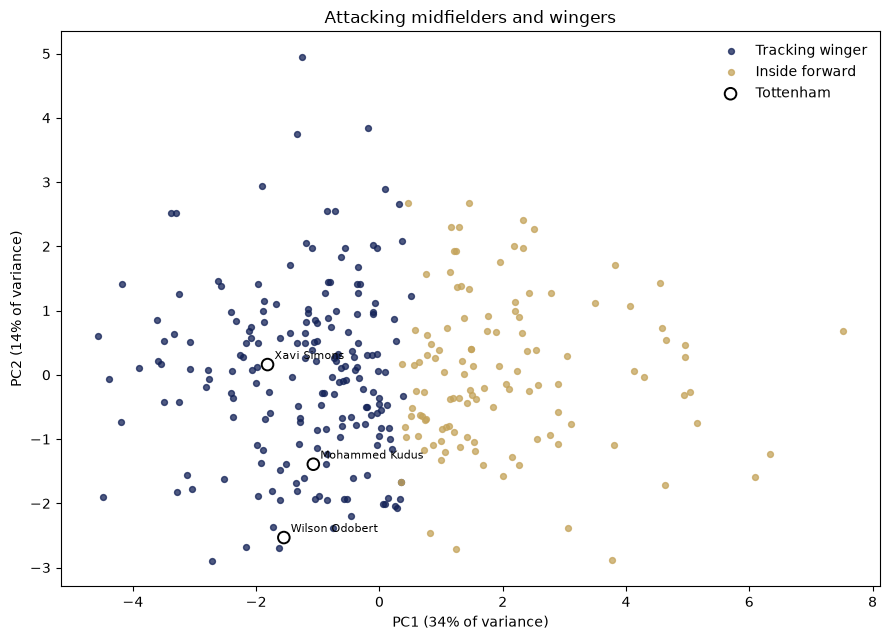

,Style,Players,High,Low,Most typical,Spurs
0,Tracking winger,192,"Tackles won per 90 (+0.18), Interceptions per ...","Goals per 90 (-0.59), Non-penalty goals per 90...","Ritsu Doan, Marco Grüll, Keane Lewis-Potter","Mohammed Kudus, Wilson Odobert, Xavi Simons"


,Style,Players,High,Low,Most typical,Spurs
0,Inside forward,117,"Goals per 90 (+0.97), Non-penalty goals per 90...","Tackles won per 90 (-0.46), Crosses per 90 (-0...","Marius Bülter, Ibrahim Mbaye, Nico Williams",none


In [5]:
show_role("AM_W")


## Strikers

Strikers


,k,silhouette
0,2,0.170
1,3,0.156
2,4,0.129
3,5,0.136
4,6,0.130


Chosen k = 2 (silhouette 0.170). Stability ARI = 1.000 (stable).


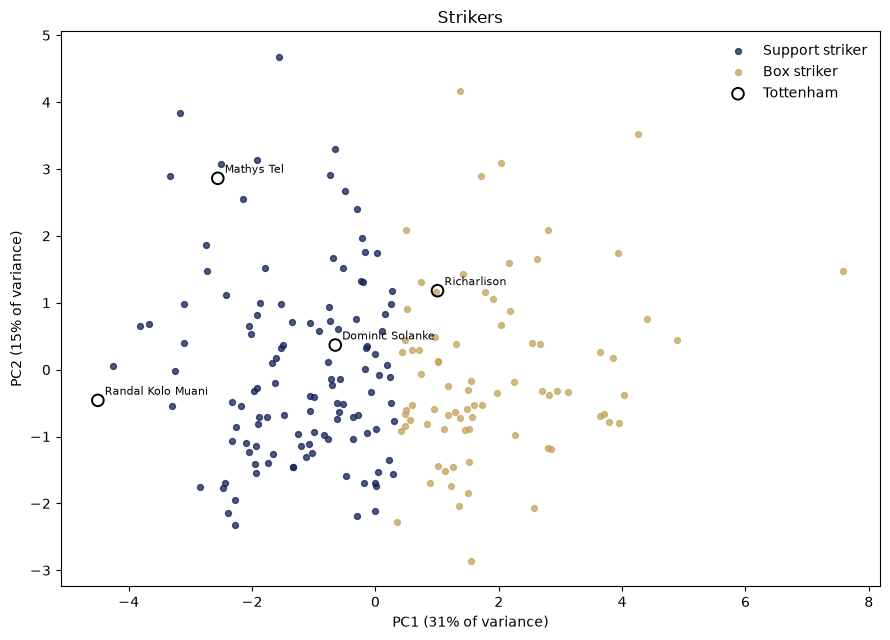

,Style,Players,High,Low,Most typical,Spurs
0,Support striker,120,"Fouls drawn per 90 (+0.21), Fouls committed pe...","Shots on target per 90 (-0.60), Goals per 90 (...","Jonathan David, Olivier Giroud, Roberto Férnandez","Dominic Solanke, Mathys Tel, Randal Kolo Muani"


,Style,Players,High,Low,Most typical,Spurs
0,Box striker,80,"Goals per 90 (+0.84), Non-penalty goals per 90...","Fouls drawn per 90 (-0.43), Interceptions per ...","Ollie Watkins, Odsonne Édouard, Folarin Balogun",Richarlison


In [6]:
show_role("ST")


## Spurs' squad by playing style

Every Tottenham player below has at least 900 minutes in 2025-26. A style with none of them is a gap. That list is the input to the later question of which kinds of player the squad does not have.

In [7]:
spurs = players.loc[players["team"] == "Tottenham"].copy()
rows = []
for position_group in ROLE_ORDER:
    for style in names.loc[names["position_group"] == position_group].itertuples(index=False):
        members = spurs.loc[
            (spurs["position_group"] == position_group) & (spurs["cluster_id"] == style.cluster_id),
            "player",
        ].tolist()
        rows.append(
            {
                "Role": position_group,
                "Style": style.cluster_name,
                "Covered": "yes" if members else "no",
                "Spurs": ", ".join(members) if members else "none",
            }
        )
coverage = pd.DataFrame(rows)
display(coverage)
print("Styles Spurs have:")
for row in coverage.loc[coverage["Covered"] == "yes"].itertuples(index=False):
    print(f"  {row.Role} — {row.Style}: {row.Spurs}")
print("Styles Spurs do not have:")
for row in coverage.loc[coverage["Covered"] == "no"].itertuples(index=False):
    print(f"  {row.Role} — {row.Style}")


,Role,Style,Covered,Spurs
0,CB,Goal-scoring centre-back,yes,"Cristian Romero, Micky van de Ven"
1,CB,Stay-at-home centre-back,yes,Kevin Danso
2,FB,Goal-scoring fullback,no,none
3,FB,Holding fullback,yes,"Destiny Udogie, Djed Spence, Pedro Porro"
4,CM,Goalscoring midfielder,yes,"Conor Gallagher, João Palhinha, Lucas Bergvall..."
5,CM,Holding midfielder,yes,"Archie Gray, Rodrigo Bentancur"
6,AM_W,Tracking winger,yes,"Mohammed Kudus, Wilson Odobert, Xavi Simons"
7,AM_W,Inside forward,no,none
8,ST,Support striker,yes,"Dominic Solanke, Mathys Tel, Randal Kolo Muani"
9,ST,Box striker,yes,Richarlison


Styles Spurs have:
  CB — Goal-scoring centre-back: Cristian Romero, Micky van de Ven
  CB — Stay-at-home centre-back: Kevin Danso
  FB — Holding fullback: Destiny Udogie, Djed Spence, Pedro Porro
  CM — Goalscoring midfielder: Conor Gallagher, João Palhinha, Lucas Bergvall, Pape Matar Sarr
  CM — Holding midfielder: Archie Gray, Rodrigo Bentancur
  AM_W — Tracking winger: Mohammed Kudus, Wilson Odobert, Xavi Simons
  ST — Support striker: Dominic Solanke, Mathys Tel, Randal Kolo Muani
  ST — Box striker: Richarlison
Styles Spurs do not have:
  FB — Goal-scoring fullback
  AM_W — Inside forward


## Limitations

Clusters only reflect the available FBref features. There is no passing, no expected goals, and no dribbling, so two players who move the ball in different ways can land in the same style if their shots, crosses, and tackles look alike.